In [38]:
from random import random, shuffle, choice, randint, seed
import matplotlib.pyplot as plt

N = 30
C = 10

seed(42)
# I handle the children as a tuple of tuples where the bools show if a child has a characteristics or not
children = tuple(
    tuple(choice([True, False]) for j in range(C))
    for i in range(N)
)

In [ ]:
# The fitness is computed as the sum of differences of adjacent children
def fitness(children: tuple[tuple[bool]], sol: list[int]) -> int:
    fitness = 0

    # I overcomplicated the loop only to not use the list indeces which are inefficient
    prev_pos = sol[-1]
    for pos in sol:
        child = children[pos]
        prev_child = children[prev_pos]

        fitness += sum(1 if c1 != c2 else 0 for c1, c2 in zip(child, prev_child))
        
        prev_pos = pos

    return fitness

# To tweak the solutuion I swap two random children for a random amount of times.
def tweak(sol: list[int]) -> list[int]:
    n = len(sol)
    new_sol = sol[:]
    first = True

    # I noticed too many swaps tend to lower the fitness a lot, so I give low probability of additional ones
    while first or random() < 0.3:
        first = False
        pos1 = randint(0, n - 1)
        pos2 = randint(0, n - 1)

        aus = new_sol[pos1]
        new_sol[pos1] = new_sol[pos2]
        new_sol[pos2] = aus

    return new_sol

In [ ]:
# The initial solution is obtained by shuffling che children positions
cur_sol = list(range(N))
shuffle(cur_sol)
cur_fitness = fitness(children, cur_sol)
iterations = 0
since_last_change = 0 #used for stopping condition

# store obtained values for plot later
best_fitnesses = [ cur_fitness ]
current_fitnesses = [ cur_fitness ]

# I stop tweaking after a lot of iterations without improvement
print("0) First candidate:", cur_sol, "- score:", cur_fitness)
while since_last_change < 20_000:
    new_sol = tweak(cur_sol)
    new_fitness = fitness(children, new_sol)
    since_last_change += 1
    iterations +=1

    current_fitnesses.append(new_fitness)

    if new_fitness > cur_fitness:
        cur_sol = new_sol
        cur_fitness = new_fitness
        since_last_change = 0

        print(f"{iterations})", "New candidate:", cur_sol, "- score:", cur_fitness)

    best_fitnesses.append(cur_fitness)

0) New candidate: [7, 29, 19, 8, 16, 27, 6, 15, 21, 10, 3, 5, 0, 12, 14, 23, 9, 24, 20, 13, 26, 25, 18, 11, 1, 17, 4, 22, 28, 2] - score: 150
1) New candidate: [12, 29, 19, 8, 16, 27, 6, 15, 21, 10, 2, 5, 0, 7, 14, 23, 9, 24, 20, 13, 26, 25, 18, 11, 1, 17, 4, 22, 28, 3] - score: 156
7) New candidate: [12, 29, 1, 8, 16, 27, 6, 15, 21, 10, 0, 5, 2, 7, 14, 23, 26, 24, 20, 13, 9, 25, 18, 11, 19, 17, 4, 22, 28, 3] - score: 162
9) New candidate: [8, 29, 1, 12, 16, 27, 6, 15, 21, 10, 0, 5, 2, 7, 14, 23, 26, 24, 20, 13, 9, 25, 18, 11, 19, 17, 4, 22, 28, 3] - score: 164
17) New candidate: [8, 29, 1, 12, 16, 27, 6, 15, 21, 10, 0, 5, 2, 7, 14, 23, 26, 24, 20, 13, 9, 3, 18, 11, 19, 17, 4, 22, 28, 25] - score: 168
31) New candidate: [8, 29, 1, 12, 16, 27, 6, 19, 21, 10, 13, 5, 2, 7, 14, 23, 26, 24, 20, 0, 9, 3, 18, 11, 15, 17, 4, 22, 28, 25] - score: 172
35) New candidate: [8, 29, 1, 12, 19, 27, 6, 16, 21, 10, 13, 5, 2, 7, 14, 23, 26, 24, 20, 0, 9, 3, 18, 11, 15, 17, 4, 22, 28, 25] - score: 174
36)

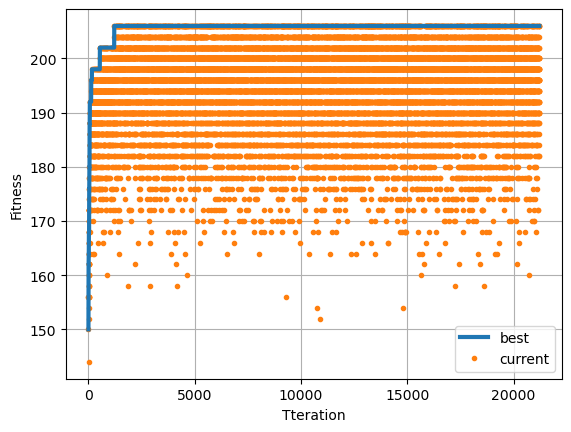

In [ ]:
# Plot the obtained fitness values
x = range(len(best_fitnesses))

plt.plot(x, best_fitnesses, '-', linewidth=3, zorder=3, label="best")
plt.plot(x, current_fitnesses, linestyle='None', marker='o', markersize=3, zorder=2, label="current")

plt.xlabel("Tteration")
plt.ylabel("Fitness")
plt.legend()
plt.grid(True)
plt.show()